## Universidade Cruzeiro do Sul

## Ciência de Dados e Aprendizado de Máquina

### 2º Semestre de 2025

# Relatório do Projeto

## Grupo

* Relatório produzido em grupo para a disciplina de Ciência de Dados e Aprendizado de Máquina.


# Classificação de Gêneros Cinematográficos a partir da Sinopse

## Identificação de um único gênero por filme com KNN e Naive Bayes

## Resumo

Este projeto apresenta o desenvolvimento de um classificador multiclasse de rótulo único capaz de atribuir um gênero cinematográfico a cada filme a partir de sua sinopse. Foi utilizado o conjunto TMDB 5000 Movie Dataset, com 4.803 registros originais. A higienização incluiu padronização de campos, tratamento de valores ausentes e vazios, interpretação da estrutura de gêneros, remoção de registros inadequados e eliminação de possíveis duplicidades. Para produzir rótulos objetivos, foram mantidos somente filmes originalmente associados a um único gênero. Em seguida, selecionaram-se as quatro classes com pelo menos 60 exemplos: Comedy, Documentary, Drama e Horror, totalizando 781 filmes. As sinopses foram representadas por TF-IDF e os algoritmos K-Nearest Neighbors e Naive Bayes Multinomial foram comparados. Os parâmetros foram ajustados por validação cruzada no conjunto de treinamento, usando F1-score macro. Na avaliação final, o Naive Bayes apresentou acurácia de 68,15% e F1-score macro de 0,556, superando o KNN, que obteve 59,24% e 0,477, respectivamente. Os resultados indicam que a sinopse contém informações úteis para a categorização, mas o desequilíbrio entre classes e a ambiguidade dos textos limitam o desempenho, principalmente nos gêneros menos representados.

## Introdução

O **TMDB 5000 Movie Dataset** reúne informações sobre filmes, incluindo título, sinopse (`overview`) e gêneros (`genres`). Neste projeto, a sinopse é utilizada como fonte de atributos para organizar automaticamente um catálogo cinematográfico.

O problema é uma **classificação multiclasse de rótulo único**: o modelo pode escolher entre vários gêneros, mas atribui exatamente um gênero a cada filme. Essa abordagem difere da classificação multirrótulo, na qual um mesmo filme poderia receber vários gêneros simultaneamente.

Como algoritmos de aprendizado de máquina trabalham com números, as sinopses são transformadas pelo **TF-IDF (Term Frequency–Inverse Document Frequency)**. Essa representação pondera as palavras conforme sua frequência em um texto e sua raridade no conjunto de documentos.

Dois algoritmos são comparados:

* **K-Nearest Neighbors (KNN):** classifica uma nova sinopse com base nos gêneros dos textos mais próximos no espaço vetorial. Neste projeto, utiliza-se a distância de cosseno.
* **Naive Bayes Multinomial:** estima probabilidades com base na distribuição das palavras em cada classe, utilizando o Teorema de Bayes e uma suposição de independência condicional entre os atributos.

Os modelos são avaliados em um conjunto de teste separado antes do treinamento. A escolha dos parâmetros utiliza somente o conjunto de treinamento, evitando que o teste influencie as decisões do modelo.

## Objetivo

### Objetivo geral

Desenvolver e comparar modelos de aprendizado de máquina capazes de atribuir **um único gênero cinematográfico** a cada filme com base em sua sinopse.

### Objetivos específicos

1. Higienizar e documentar o tratamento do dataset.
2. Construir uma variável-alvo multiclasse de rótulo único.
3. Analisar a distribuição dos gêneros e das sinopses.
4. Transformar os textos em atributos numéricos por TF-IDF.
5. Treinar e ajustar os algoritmos KNN e Naive Bayes Multinomial.
6. Comparar os modelos por acurácia, precision, recall, F1-score e matriz de confusão.
7. Demonstrar a utilização do melhor modelo em uma função de previsão e em um pequeno catálogo.

## Desenvolvimento

### Parte 1 — Importação das bibliotecas e dos dados

As bibliotecas abaixo são utilizadas para manipulação dos dados, visualização, vetorização de texto, treinamento, ajuste de parâmetros e avaliação. O valor `RANDOM_STATE = 42` torna as divisões e a validação cruzada reproduzíveis.

In [1]:
%matplotlib inline

import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn

from IPython.display import display
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_recall_fscore_support,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline

RANDOM_STATE = 42
print(f'Pandas: {pd.__version__}')
print(f'Scikit-learn: {sklearn.__version__}')

Pandas: 2.3.2
Scikit-learn: 1.7.2


O arquivo `tmdb_5000_movies.csv` deve estar no mesmo diretório do notebook. Também são verificados os diretórios `/content`, utilizado no Google Colab, e o diretório de execução deste projeto. Caso o arquivo não seja encontrado, uma mensagem orienta o envio do dataset.

In [2]:
NOME_ARQUIVO = 'tmdb_5000_movies.csv'
diretorios_possiveis = [
    Path.cwd(),
    Path('/content'),
    Path('/mnt/agents/upload'),
]

caminhos = [pasta / NOME_ARQUIVO for pasta in diretorios_possiveis]
CAMINHO_DATASET = next((caminho for caminho in caminhos if caminho.exists()), None)

if CAMINHO_DATASET is None:
    raise FileNotFoundError(
        f'Arquivo {NOME_ARQUIVO} não encontrado. Envie o CSV para o mesmo diretório do notebook.'
    )

df_original = pd.read_csv(CAMINHO_DATASET)
print(f'Dataset carregado de: {CAMINHO_DATASET}')
print(f'Dimensões: {df_original.shape[0]} linhas e {df_original.shape[1]} colunas')
display(df_original[['id', 'title', 'overview', 'genres']].head())

Dataset carregado de: /mnt/agents/upload/tmdb_5000_movies.csv
Dimensões: 4803 linhas e 20 colunas


,id,title,overview,genres
0,19995,Avatar,"In the 22nd century, a paraplegic Marine is di...","[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam..."
1,285,Pirates of the Caribbean: At World's End,"Captain Barbossa, long believed to be dead, ha...","[{""id"": 12, ""name"": ""Adventure""}, {""id"": 14, ""..."
2,206647,Spectre,A cryptic message from Bond’s past sends him o...,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam..."
3,49026,The Dark Knight Rises,Following the death of District Attorney Harve...,"[{""id"": 28, ""name"": ""Action""}, {""id"": 80, ""nam..."
4,49529,John Carter,"John Carter is a war-weary, former military ca...","[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam..."


Antes da higienização, verificamos os tipos, os valores ausentes e a estrutura dos campos necessários. A coluna `genres` contém objetos em formato JSON e precisa ser convertida em listas de nomes.

In [3]:
print('Informações gerais:')
df_original[['title', 'overview', 'genres']].info()

print()
print('Valores ausentes nas colunas utilizadas:')
display(df_original[['title', 'overview', 'genres']].isna().sum().to_frame('Valores ausentes'))

print()
print('Duplicidades exatas no dataset original:', df_original.duplicated().sum())

Informações gerais:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4803 entries, 0 to 4802
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   title     4803 non-null   object
 1   overview  4800 non-null   object
 2   genres    4803 non-null   object
dtypes: object(3)
memory usage: 112.7+ KB

Valores ausentes nas colunas utilizadas:


,Valores ausentes
title,0
overview,3
genres,0



Duplicidades exatas no dataset original: 0


### Parte 2 — Higienização do dataset

A higienização é realizada em etapas registradas em uma tabela de auditoria:

1. **Seleção das colunas:** são mantidos identificador, título, sinopse e gêneros.
2. **Padronização:** títulos e sinopses são convertidos para texto e têm espaços nas extremidades removidos.
3. **Valores ausentes ou vazios:** registros sem título ou sinopse são excluídos.
4. **Interpretação dos gêneros:** o conteúdo JSON é convertido em uma lista de nomes; estruturas inválidas resultam em lista vazia e são posteriormente removidas.
5. **Rótulo único:** somente filmes originalmente associados a exatamente um gênero permanecem. Assim, não é necessário escolher arbitrariamente um gênero principal para filmes multirrótulo.
6. **Qualidade mínima da sinopse:** textos com menos de 20 caracteres são removidos.
7. **Duplicidades:** são eliminadas possíveis repetições exatas da combinação título, sinopse e gênero.
8. **Classes viáveis:** para reduzir o problema de classes muito pequenas, permanecem os gêneros com pelo menos 60 filmes.

O limite de 60 exemplos é uma decisão de escopo baseada na distribuição observada, e não uma regra universal. Ele permite incluir quatro classes e manter quantidade suficiente de registros para divisão estratificada e validação cruzada.

In [4]:
def extrair_generos(conteudo):
    """Converte o campo JSON em uma lista de nomes de gêneros."""
    if pd.isna(conteudo):
        return []
    try:
        dados = json.loads(conteudo) if isinstance(conteudo, str) else conteudo
        return [
            str(item['name']).strip()
            for item in dados
            if isinstance(item, dict) and item.get('name')
        ]
    except (json.JSONDecodeError, TypeError, KeyError):
        return []

# Cada etapa é registrada para tornar a higienização auditável.
df = df_original[['id', 'title', 'overview', 'genres']].copy()
auditoria = [('Dataset original', len(df))]

# Padronização de textos e tratamento de valores ausentes.
df['title'] = df['title'].fillna('').astype(str).str.strip()
df['overview'] = df['overview'].fillna('').astype(str).str.strip()
df = df[(df['title'] != '') & (df['overview'] != '')].copy()
auditoria.append(('Após remover títulos/sinopses vazios', len(df)))

# Conversão da estrutura JSON e remoção de registros sem gênero válido.
df['lista_generos'] = df['genres'].apply(extrair_generos)
df = df[df['lista_generos'].str.len() > 0].copy()
auditoria.append(('Após remover registros sem gênero', len(df)))

# O projeto utiliza uma única classe por filme.
df = df[df['lista_generos'].str.len() == 1].copy()
df['genero'] = df['lista_generos'].str[0]
auditoria.append(('Após manter filmes com um único gênero', len(df)))

# Qualidade mínima do texto e remoção de duplicidades exatas.
df = df[df['overview'].str.len() >= 20].copy()
auditoria.append(('Após remover sinopses com menos de 20 caracteres', len(df)))
df = df.drop_duplicates(subset=['title', 'overview', 'genero']).copy()
auditoria.append(('Após remover duplicidades exatas', len(df)))

# Seleção das classes com quantidade mínima de exemplos.
MINIMO_POR_GENERO = 60
contagem_geral = df['genero'].value_counts()
generos_selecionados = contagem_geral[contagem_geral >= MINIMO_POR_GENERO].index.tolist()
df = df[df['genero'].isin(generos_selecionados)].copy()
auditoria.append(('Após selecionar gêneros com pelo menos 60 filmes', len(df)))

df_modelagem = df.reset_index(drop=True)
tabela_auditoria = pd.DataFrame(auditoria, columns=['Etapa', 'Registros restantes'])
display(tabela_auditoria)
print('Gêneros selecionados:', generos_selecionados)
print('Dimensões finais:', df_modelagem.shape)

,Etapa,Registros restantes
0,Dataset original,4803
1,Após remover títulos/sinopses vazios,4799
2,Após remover registros sem gênero,4771
3,Após manter filmes com um único gênero,897
4,Após remover sinopses com menos de 20 caracteres,897
5,Após remover duplicidades exatas,897
6,Após selecionar gêneros com pelo menos 60 filmes,781


Gêneros selecionados: ['Drama', 'Comedy', 'Documentary', 'Horror']
Dimensões finais: (781, 6)


O recorte final contém **781 filmes** e quatro classes. A redução de 4.803 para 781 registros decorre principalmente da decisão de utilizar apenas filmes com um gênero original e de excluir classes com poucos exemplos. Essa redução é uma limitação do estudo: o modelo se aplica ao catálogo formado pelos quatro gêneros selecionados, e não a todos os gêneros do TMDB.

In [5]:
# Conferências finais após a higienização.
assert not df_modelagem[['title', 'overview', 'genero']].isna().any().any()
assert (df_modelagem['overview'].str.strip() != '').all()
assert (df_modelagem['overview'].str.len() >= 20).all()
assert not df_modelagem.duplicated(['title', 'overview', 'genero']).any()
assert df_modelagem['genero'].nunique() == 4

print('Todas as verificações de consistência foram concluídas.')
display(df_modelagem[['title', 'overview', 'genero']].head())

Todas as verificações de consistência foram concluídas.


,title,overview,genero
0,Fun with Dick and Jane,After Dick Harper loses his job at Globodyne i...,Comedy
1,Australia,"Set in northern Australia before World War II,...",Drama
2,The Perfect Storm,"In October 1991, a confluence of weather condi...",Drama
3,The Aviator,A biopic depicting the life of filmmaker and a...,Drama
4,Gulliver's Travels,Travel writer Lemuel Gulliver takes an assignm...,Comedy


### Parte 3 — Análise exploratória

A distribuição das classes é importante porque o dataset é desequilibrado: Drama e Comedy possuem muito mais registros que Documentary e Horror. Por esse motivo, a acurácia será complementada por métricas macro, que atribuem o mesmo peso a cada gênero.

,Quantidade,Percentual
genero,,
Drama,369,47.25
Comedy,282,36.11
Documentary,66,8.45
Horror,64,8.19


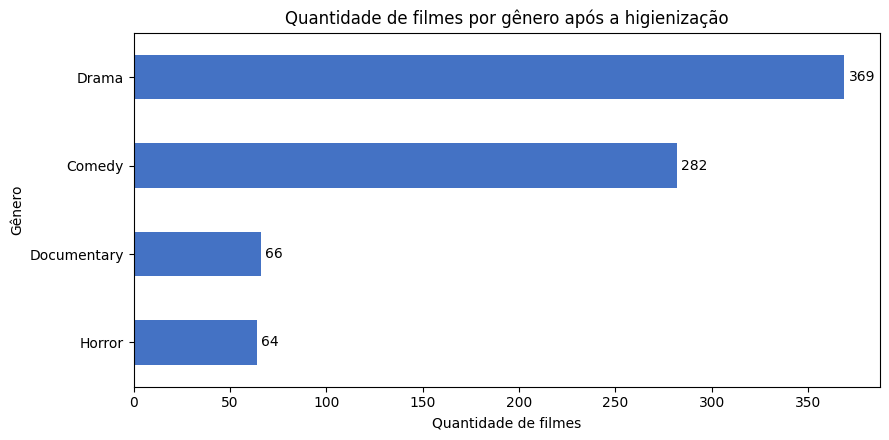

In [6]:
contagem_classes = df_modelagem['genero'].value_counts()
tabela_classes = contagem_classes.to_frame('Quantidade')
tabela_classes['Percentual'] = 100 * contagem_classes / len(df_modelagem)
display(tabela_classes.round(2))

fig, ax = plt.subplots(figsize=(9, 4.5))
contagem_classes.sort_values().plot(kind='barh', color='#4472C4', ax=ax)
ax.set_title('Quantidade de filmes por gênero após a higienização')
ax.set_xlabel('Quantidade de filmes')
ax.set_ylabel('Gênero')
for container in ax.containers:
    ax.bar_label(container, padding=3)
plt.tight_layout()
plt.show()

Também analisamos o tamanho das sinopses. Essa verificação ajuda a identificar textos muito curtos e diferenças de extensão entre os gêneros. Não utilizamos o tamanho como atributo isolado; ele entra no modelo somente indiretamente, por meio das palavras representadas pelo TF-IDF.

,Quantidade,Media_palavras,Mediana_palavras,Minimo_palavras,Maximo_palavras
genero,,,,,
Comedy,282,47.9,43.5,9,142
Documentary,66,63.5,58.5,9,165
Drama,369,51.6,44.0,9,164
Horror,64,47.5,44.0,13,98


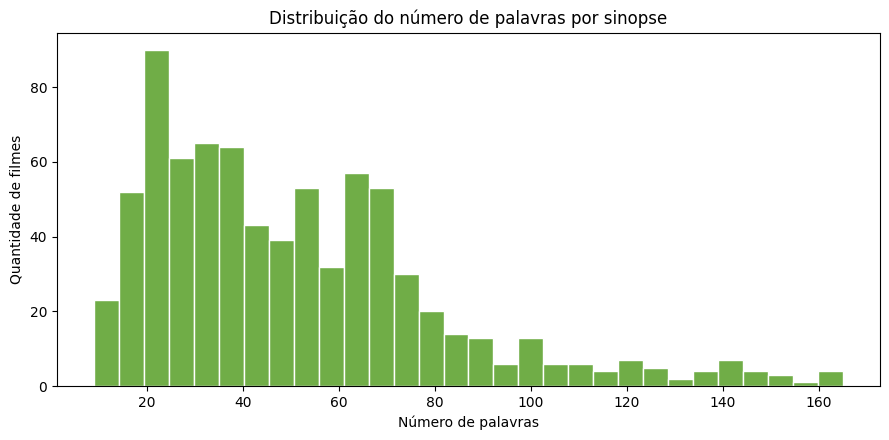

In [7]:
df_modelagem['qtd_caracteres'] = df_modelagem['overview'].str.len()
df_modelagem['qtd_palavras'] = df_modelagem['overview'].str.split().str.len()

resumo_textos = df_modelagem.groupby('genero').agg(
    Quantidade=('title', 'size'),
    Media_palavras=('qtd_palavras', 'mean'),
    Mediana_palavras=('qtd_palavras', 'median'),
    Minimo_palavras=('qtd_palavras', 'min'),
    Maximo_palavras=('qtd_palavras', 'max'),
)
display(resumo_textos.round(1))

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(df_modelagem['qtd_palavras'], bins=30, color='#70AD47', edgecolor='white')
ax.set_title('Distribuição do número de palavras por sinopse')
ax.set_xlabel('Número de palavras')
ax.set_ylabel('Quantidade de filmes')
plt.tight_layout()
plt.show()

### Parte 4 — Separação entre treinamento e teste

Os dados são divididos em 80% para treinamento e 20% para teste. A estratificação preserva aproximadamente a proporção de cada gênero. O teste permanece separado durante todo o ajuste de parâmetros.

In [8]:
X = df_modelagem['overview']
y = df_modelagem['genero']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y,
)

print(f'Treinamento: {len(X_train)} filmes')
print(f'Teste: {len(X_test)} filmes')
print()
print('Distribuição no treinamento:')
display(y_train.value_counts().to_frame('Quantidade'))
print()
print('Distribuição no teste:')
display(y_test.value_counts().to_frame('Quantidade'))

Treinamento: 624 filmes
Teste: 157 filmes

Distribuição no treinamento:


,Quantidade
genero,
Drama,295
Comedy,225
Documentary,53
Horror,51



Distribuição no teste:


,Quantidade
genero,
Drama,74
Comedy,57
Horror,13
Documentary,13


### Parte 5 — Vetorização, modelos e ajuste de parâmetros

Cada modelo é colocado em um `Pipeline` com duas etapas: TF-IDF e classificador. Isso garante que, em cada divisão da validação cruzada, o vocabulário e os pesos TF-IDF sejam ajustados somente com os textos de treinamento daquela divisão.

Configurações comuns do TF-IDF:

* conversão para letras minúsculas;
* normalização de acentos;
* remoção de stop words em inglês, idioma das sinopses;
* exclusão de termos presentes em mais de 95% dos documentos;
* aplicação de escala sublinear à frequência dos termos.

Os grids avaliam palavras isoladas (`unigramas`) e a combinação de palavras isoladas com pares adjacentes (`bigramas`). A validação cruzada estratificada possui três divisões e utiliza o F1-score macro como métrica de seleção.

In [9]:
def criar_tfidf():
    return TfidfVectorizer(
        lowercase=True,
        strip_accents='unicode',
        stop_words='english',
        max_df=0.95,
        sublinear_tf=True,
    )

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

pipeline_nb = Pipeline([
    ('tfidf', criar_tfidf()),
    ('modelo', MultinomialNB()),
])

pipeline_knn = Pipeline([
    ('tfidf', criar_tfidf()),
    ('modelo', KNeighborsClassifier(
        algorithm='brute',
        metric='cosine',
        n_jobs=-1,
    )),
])

#### Naive Bayes Multinomial

No Naive Bayes, o parâmetro `alpha` controla a suavização das probabilidades. Valores menores dão mais peso às frequências observadas; valores maiores reduzem o impacto de termos raros ou ausentes. Também são avaliadas diferentes configurações de vocabulário.

In [10]:
parametros_nb = {
    'tfidf__ngram_range': [(1, 1), (1, 2)],
    'tfidf__min_df': [1, 2],
    'modelo__alpha': [0.1, 0.5, 1.0],
}

busca_nb = GridSearchCV(
    estimator=pipeline_nb,
    param_grid=parametros_nb,
    scoring='f1_macro',
    cv=cv,
    n_jobs=-1,
    return_train_score=True,
)
busca_nb.fit(X_train, y_train)

print('Melhor F1 macro na validação cruzada:', round(busca_nb.best_score_, 4))
print('Melhores parâmetros:')
for parametro, valor in busca_nb.best_params_.items():
    print(f'  {parametro}: {valor}')

Melhor F1 macro na validação cruzada: 0.492
Melhores parâmetros:
  modelo__alpha: 0.1
  tfidf__min_df: 2
  tfidf__ngram_range: (1, 2)


#### K-Nearest Neighbors

No KNN, `n_neighbors` define quantas sinopses próximas participam da decisão. São comparados votos uniformes e votos ponderados pela distância. A distância de cosseno é apropriada para comparar a direção dos vetores TF-IDF, reduzindo a influência direta do tamanho dos textos.

In [11]:
parametros_knn = {
    'tfidf__ngram_range': [(1, 1), (1, 2)],
    'tfidf__min_df': [1, 2],
    'modelo__n_neighbors': [3, 5, 7, 11, 15],
    'modelo__weights': ['uniform', 'distance'],
}

busca_knn = GridSearchCV(
    estimator=pipeline_knn,
    param_grid=parametros_knn,
    scoring='f1_macro',
    cv=cv,
    n_jobs=-1,
    return_train_score=True,
)
busca_knn.fit(X_train, y_train)

print('Melhor F1 macro na validação cruzada:', round(busca_knn.best_score_, 4))
print('Melhores parâmetros:')
for parametro, valor in busca_knn.best_params_.items():
    print(f'  {parametro}: {valor}')

Melhor F1 macro na validação cruzada: 0.4853
Melhores parâmetros:
  modelo__n_neighbors: 5
  modelo__weights: distance
  tfidf__min_df: 1
  tfidf__ngram_range: (1, 1)


### Parte 6 — Avaliação e comparação dos modelos

Somente após o ajuste, os melhores pipelines são aplicados ao conjunto de teste. São calculadas as seguintes métricas:

* **Acurácia:** proporção total de acertos.
* **Precision macro:** média da precisão de cada gênero, sem ponderar pelo tamanho da classe.
* **Recall macro:** média da capacidade de recuperar os filmes de cada gênero.
* **F1 macro:** média harmônica entre precision e recall por classe, seguida da média entre classes. É a métrica principal do projeto.
* **F1 weighted:** média do F1 ponderada pela quantidade de exemplos de cada classe.

As matrizes de confusão mostram quais gêneros são confundidos entre si.

In [12]:
def calcular_metricas(y_real, y_previsto):
    """Resume as métricas globais de um classificador."""
    precision_macro, recall_macro, f1_macro, _ = precision_recall_fscore_support(
        y_real, y_previsto, average='macro', zero_division=0
    )
    _, _, f1_weighted, _ = precision_recall_fscore_support(
        y_real, y_previsto, average='weighted', zero_division=0
    )
    return {
        'Acuracia': accuracy_score(y_real, y_previsto),
        'Precision_macro': precision_macro,
        'Recall_macro': recall_macro,
        'F1_macro': f1_macro,
        'F1_weighted': f1_weighted,
    }

buscas = {
    'Naive Bayes': busca_nb,
    'KNN': busca_knn,
}

previsoes = {}
resultados = []
for nome, busca in buscas.items():
    previsoes[nome] = busca.best_estimator_.predict(X_test)
    resultados.append({'Modelo': nome, **calcular_metricas(y_test, previsoes[nome])})

comparacao = pd.DataFrame(resultados).set_index('Modelo')
display(comparacao.round(4))

,Acuracia,Precision_macro,Recall_macro,F1_macro,F1_weighted
Modelo,,,,,
Naive Bayes,0.6815,0.7588,0.5097,0.5558,0.6607
KNN,0.5924,0.6907,0.4365,0.4773,0.5685


In [13]:
for nome in buscas:
    print()
    print(f'Relatório de classificação — {nome}')
    print(classification_report(y_test, previsoes[nome], zero_division=0))


Relatório de classificação — Naive Bayes
              precision    recall  f1-score   support

      Comedy       0.73      0.65      0.69        57
 Documentary       1.00      0.38      0.56        13
       Drama       0.64      0.85      0.73        74
      Horror       0.67      0.15      0.25        13

    accuracy                           0.68       157
   macro avg       0.76      0.51      0.56       157
weighted avg       0.70      0.68      0.66       157


Relatório de classificação — KNN
              precision    recall  f1-score   support

      Comedy       0.57      0.47      0.52        57
 Documentary       1.00      0.23      0.38        13
       Drama       0.59      0.81      0.68        74
      Horror       0.60      0.23      0.33        13

    accuracy                           0.59       157
   macro avg       0.69      0.44      0.48       157
weighted avg       0.62      0.59      0.57       157



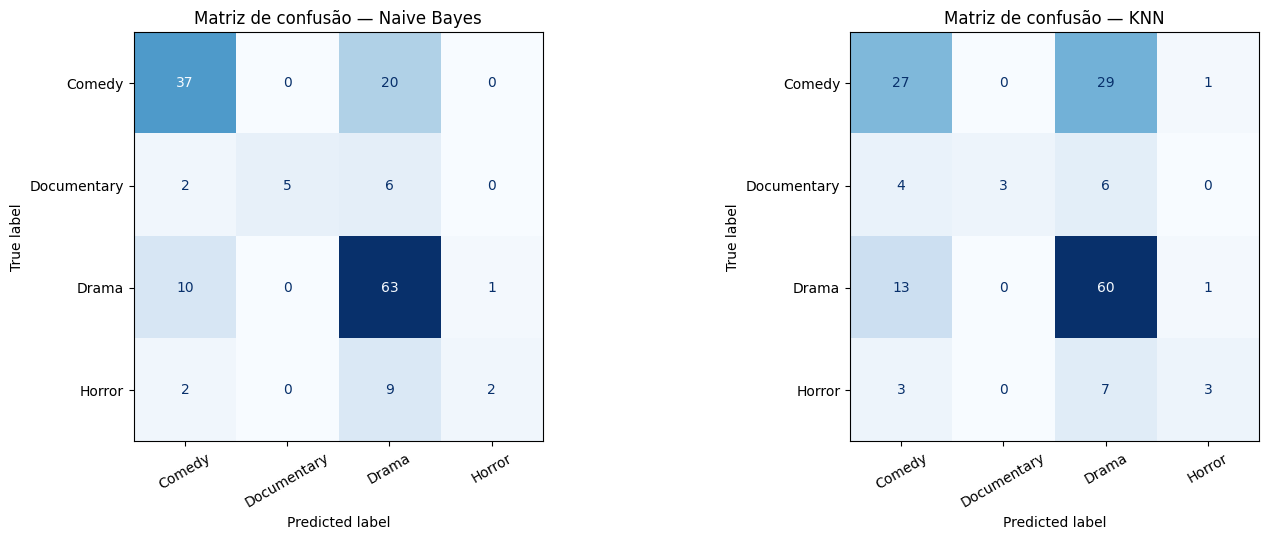

In [14]:
ordem_classes = sorted(y.unique())
fig, eixos = plt.subplots(1, 2, figsize=(15, 5.5))

for eixo, nome in zip(eixos, buscas):
    matriz = confusion_matrix(y_test, previsoes[nome], labels=ordem_classes)
    visualizacao = ConfusionMatrixDisplay(matriz, display_labels=ordem_classes)
    visualizacao.plot(ax=eixo, cmap='Blues', values_format='d', colorbar=False)
    eixo.set_title(f'Matriz de confusão — {nome}')
    eixo.tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

#### Interpretação dos resultados

O **Naive Bayes** obteve o melhor resultado no conjunto de teste: acurácia de aproximadamente **68,15%** e F1 macro de **0,556**. O KNN alcançou aproximadamente **59,24%** de acurácia e F1 macro de **0,477**.

O Naive Bayes recuperou bem os filmes de Drama, mas apresentou recall menor em Documentary e, principalmente, Horror. Isso mostra que uma boa acurácia global não significa desempenho uniforme: as classes majoritárias influenciam mais a acurácia, enquanto o F1 macro evidencia as dificuldades nas classes menos representadas. O KNN também concentrou muitas previsões nas categorias mais frequentes.

Esses resultados são plausíveis para sinopses curtas: filmes de gêneros distintos podem compartilhar vocabulário e elementos narrativos. Além disso, a classificação de rótulo único não representa filmes que, na realidade, combinam vários gêneros.

### Parte 7 — Análise de exemplos classificados incorretamente

A inspeção dos erros complementa as métricas e permite verificar a ambiguidade das sinopses. A tabela apresenta até oito exemplos, com textos abreviados apenas para facilitar a leitura; os modelos utilizaram sempre a sinopse completa.

In [15]:
melhor_nome_preliminar = comparacao['F1_macro'].idxmax()
erros = df_modelagem.loc[X_test.index, ['title', 'overview', 'genero']].copy()
erros['genero_previsto'] = previsoes[melhor_nome_preliminar]
erros = erros[erros['genero'] != erros['genero_previsto']].copy()
erros['overview'] = erros['overview'].str.slice(0, 180) + '...'

print(f'Quantidade de erros do modelo {melhor_nome_preliminar}: {len(erros)}')
display(erros[['title', 'genero', 'genero_previsto', 'overview']].head(8))

Quantidade de erros do modelo Naive Bayes: 50


,title,genero,genero_previsto,overview
259,The Fog,Horror,Drama,Strange things begin to occurs as a tiny Calif...
305,All About Steve,Comedy,Drama,"After one short date, a brilliant crossword co..."
620,The 41–Year–Old Virgin Who Knocked Up Sarah Ma...,Comedy,Drama,"Follows Andy, who needs to hook up with a hott..."
332,St. Vincent,Comedy,Drama,A young boy whose parents just divorced finds ...
774,Slacker,Comedy,Drama,"Presents a day in the life in Austin, Texas am..."
408,You Got Served,Drama,Comedy,"At Mr. Rad's Warehouse, the best hip-hop crews..."
96,Alfie,Comedy,Drama,"In Manhattan, the British limousine driver Alf..."
128,Wanderlust,Comedy,Drama,"Rattled by sudden unemployment, a Manhattan co..."


### Parte 8 — Demonstração da previsão e do catálogo

O modelo com maior F1 macro é selecionado automaticamente. A função abaixo valida a entrada e retorna exatamente um dos quatro gêneros conhecidos. As frases seguintes são exemplos inéditos criados apenas para demonstrar o uso; não fazem parte do treinamento nem do teste.

In [16]:
busca_vencedora = buscas[comparacao['F1_macro'].idxmax()]
modelo_final = busca_vencedora.best_estimator_

def prever_genero(sinopse):
    """Recebe uma sinopse em inglês e retorna um único gênero previsto."""
    if not isinstance(sinopse, str) or not sinopse.strip():
        raise ValueError('Informe uma sinopse textual não vazia.')
    return modelo_final.predict([sinopse.strip()])[0]

sinopses_exemplo = [
    'Two mismatched friends try to plan a wedding, but every decision turns into a hilarious disaster.',
    'A group of teenagers is trapped in a haunted house and terrorized by a bloodthirsty ghost.',
    'Through archival footage and interviews, this film examines the lives of workers and the history of their community.',
]

for sinopse in sinopses_exemplo:
    print(f'Gênero previsto: {prever_genero(sinopse)}')
    print(f'Sinopse: {sinopse}')
    print()

Gênero previsto: Comedy
Sinopse: Two mismatched friends try to plan a wedding, but every decision turns into a hilarious disaster.

Gênero previsto: Horror
Sinopse: A group of teenagers is trapped in a haunted house and terrorized by a bloodthirsty ghost.

Gênero previsto: Documentary
Sinopse: Through archival footage and interviews, this film examines the lives of workers and the history of their community.



Para demonstrar a organização do catálogo, aplicamos o modelo final aos filmes do conjunto de teste. A coluna `genero` representa o rótulo original e `genero_previsto` mostra a categoria atribuída pelo classificador. Em uma aplicação real, o gênero previsto poderia ser usado como filtro de navegação, com indicação de que se trata de uma classificação automática.

In [17]:
catalogo = df_modelagem.loc[X_test.index, ['title', 'overview', 'genero']].copy()
catalogo['genero_previsto'] = modelo_final.predict(X_test)
catalogo = catalogo.sort_values(['genero_previsto', 'title'])

# Exibe até três exemplos de cada categoria prevista.
amostra_catalogo = catalogo.groupby('genero_previsto', group_keys=False).head(3)
display(amostra_catalogo[['title', 'genero', 'genero_previsto']])

print('Quantidade de filmes por categoria prevista no teste:')
display(catalogo['genero_previsto'].value_counts().to_frame('Quantidade'))

,title,genero,genero_previsto
189,A Lot Like Love,Comedy,Comedy
275,ATL,Drama,Comedy
522,Adore,Drama,Comedy
657,A LEGO Brickumentary,Documentary,Documentary
566,Freakonomics,Documentary,Documentary
759,Indie Game: The Movie,Documentary,Documentary
83,17 Again,Comedy,Drama
671,1982,Drama,Drama
492,90 Minutes in Heaven,Drama,Drama
552,A Nightmare on Elm Street Part 2: Freddy's Rev...,Horror,Horror


Quantidade de filmes por categoria prevista no teste:


,Quantidade
genero_previsto,
Drama,98
Comedy,51
Documentary,5
Horror,3


### Parte 9 — Estudo de caso: diagnóstico do erro do filme *The Fog*

Nesta seção, investigamos em profundidade um erro concreto cometido por ambos os modelos: o filme **The Fog** (1980), de gênero **Horror**, foi classificado como **Drama** pelo Naive Bayes e pelo KNN. O objetivo é entender *por que* o erro ocorreu, transformando-o em um caso de uso documentado das limitações do classificador.

#### O filme e o erro

*The Fog* é um filme de terror sobrenatural. Sua sinopse, porém, é eufemística: descreve eventos estranhos em uma cidade costeira sem empregar o vocabulário típico do gênero. A sinopse lida como um mistério dramático, e foi exatamente assim que os dois modelos a interpretaram.

#### Diagnóstico

A análise da contribuição dos termos (diferença de log-probabilidades entre Drama e Horror no Naive Bayes) revela três causas combinadas:

1. **Sinopse eufemística.** Os termos que mais evidenciam horror — `mysterious`, `strange`, `dark` — favorecem Horror, mas com peso insuficiente. Termos explícitos do gênero (`ghost`, `demon`, `curse`) simplesmente **não aparecem na sinopse**.
2. **Vocabulário narrativo genérico.** Os termos centrais da sinopse (`life`, `discovers`, `secret`, `witnesses`, `radio`, `people`) são frequentes em sinopses de **Drama** e raríssimos em sinopses de **Horror**. No Naive Bayes, cada um desses termos acumula evidência para Drama, e a soma domina a decisão final.
3. **Desequilíbrio de classes e suavização.** Horror tem apenas 51 filmes no treinamento contra 295 de Drama. Com `min_df = 2` e suavização `alpha = 0.1`, termos ausentes das poucas sinopses de Horror recebem probabilidade mínima (log-probabilidade próxima de `-8,5`), o que impede que evidências fracas de Horror vençam a massa de evidências de Drama.

O KNN concorda com o erro: os 5 vizinhos mais próximos estão todos a distância de cosseno acima de `0,89`, ou seja, não existe nenhuma sinopse de treinamento realmente parecida — a sinopse do filme fica em uma região ambígua do espaço vetorial, onde a maioria dos vizinhos é de Drama.

#### Conclusão do caso

*The Fog* é um **falso negativo típico de Horror**: ilustra o recall baixo do gênero (0,15 no Naive Bayes) e mostra que o classificador depende fortemente da presença de marcadores lexicais explícitos. Sinopses que sugerem o gênero indiretamente, por atmosfera e narrativa em vez de vocabulário, tendem a ser absorvidas pela classe majoritária Drama. A célula a seguir reproduz o diagnóstico com os modelos treinados.


In [ ]:
# Localiza The Fog no conjunto de teste e exibe o erro dos dois modelos.
fog = df_modelagem.loc[X_test.index]
fog = fog[fog['title'] == 'The Fog'][['title', 'overview', 'genero']]
display(fog)
sinopse_fog = fog['overview'].iloc[0]

for nome, busca in buscas.items():
    modelo = busca.best_estimator_
    proba = modelo.predict_proba([sinopse_fog])[0]
    print(f"{nome}: previsto={modelo.predict([sinopse_fog])[0]} (real=Horror)")
    print(f"  probabilidades: {dict(zip(modelo.classes_, proba.round(4)))}")
    print()

# Diagnóstico no Naive Bayes: contribuição de cada termo da sinopse
# para Drama versus Horror (diferença de log-probabilidades).
nb = buscas['Naive Bayes'].best_estimator_
vetorizador = nb.named_steps['tfidf']
classificador = nb.named_steps['modelo']

X_fog = vetorizador.transform([sinopse_fog])
termos_fog = X_fog.indices
nomes = np.array(vetorizador.get_feature_names_out())
i_drama = list(classificador.classes_).index('Drama')
i_horror = list(classificador.classes_).index('Horror')

delta = (classificador.feature_log_prob_[i_drama][termos_fog]
         - classificador.feature_log_prob_[i_horror][termos_fog])
quadro = (pd.DataFrame({'termo': nomes[termos_fog], 'delta_logP_Drama_menos_Horror': delta.round(3)})
          .sort_values('delta_logP_Drama_menos_Horror', ascending=False))

print('Termos que MAIS favorecem Drama (erro acumulado):')
display(quadro.head(10))
print('Termos que favorecem Horror (evidência insuficiente):')
display(quadro.tail(5))

vocabulario = set(vetorizador.get_feature_names_out())
for termo in ['ghost', 'demon', 'curse', 'mysterious', 'strange', 'dark']:
    print(f"termo '{termo}': presente na sinopse={termo in sinopse_fog.lower()}, no vocabulário={termo in vocabulario}")


### Parte 10 — Aplicação web: monorepo com frontend e backend

O projeto foi estendido para uma aplicação web servida por um repositório monorepo, com o objetivo de **demonstrar a performance de ambos os algoritmos em um cenário de análise real**. O escopo é descrito a seguir; o código completo não faz parte deste notebook.

#### Escopo e arquitetura

* **Backend (FastAPI):** replica integralmente o pipeline deste notebook — higienização do dataset, recorte de rótulo único, vetorização TF-IDF e os pipelines de Naive Bayes e KNN com os parâmetros ajustados por validação cruzada. Expõe endpoints REST para listar filmes, consultar detalhes e prever gêneros por sinopse ou por identificador de filme.
* **Frontend (página web simples):** interface em que o usuário filtra e seleciona **um único filme**, escolhe o algoritmo (Naive Bayes ou KNN) e solicita a previsão. A resposta exibe o gênero previsto, a distribuição de confiança entre as quatro classes e o gênero real do filme para comparação imediata.

#### Proposta: previsões honestas sobre dados de teste

A decisão metodológica central da aplicação é que **os modelos servidos são treinados apenas com os 80% de treinamento**, e o frontend lista **somente os 157 filmes do conjunto de teste**. Dessa forma, cada previsão é fora da amostra: o modelo nunca viu a sinopse selecionada, e os acertos e erros exibidos correspondem ao desempenho real reportado neste relatório (acurácia de 68,15% para o Naive Bayes e 59,24% para o KNN).

Na demonstração ao vivo, é possível percorrer filmes do catálogo e observar os dois classificadores acertando e errando em tempo real — incluindo casos documentados como o de *The Fog* — reforçando de forma prática as conclusões sobre desequilíbrio de classes, ambiguidade das sinopses e a diferença de desempenho entre os algoritmos.


## Conclusão

O projeto atingiu o objetivo de construir um classificador multiclasse capaz de atribuir um único gênero a cada filme a partir da sinopse. A higienização foi essencial para transformar o campo de gêneros, eliminar registros inadequados e criar uma variável-alvo coerente com a proposta. O recorte final reuniu 781 filmes distribuídos entre Comedy, Documentary, Drama e Horror.

O **Naive Bayes Multinomial** foi o melhor modelo, com acurácia de aproximadamente **68,15%**, F1 macro de **0,556** e F1 weighted de **0,661**. Seus melhores parâmetros foram `alpha = 0.1`, `min_df = 2` e uso de unigramas e bigramas no TF-IDF. O KNN obteve acurácia de aproximadamente **59,24%** e F1 macro de **0,477**, com `k = 5`, votos ponderados pela distância, unigramas e `min_df = 1`.

Na comparação, o Naive Bayes contribuiu mais para a organização automática do catálogo, mas o desempenho variou entre os gêneros. O desequilíbrio das classes, a semelhança vocabular entre sinopses e a subjetividade dos gêneros explicam parte dos erros. Portanto, o modelo é uma demonstração funcional, não um classificador definitivo para produção.

Como trabalhos futuros, recomenda-se ampliar o dataset, utilizar validação com mais divisões, testar outras representações textuais e algoritmos lineares e avaliar estratégias para melhorar o recall das classes minoritárias. Também seria possível desenvolver uma versão multirrótulo, caso o catálogo volte a admitir vários gêneros por filme.

O estudo de caso do filme *The Fog* (Parte 9) aprofundou a análise dos erros: o diagnóstico mostrou que sinopses eufemísticas, sem marcadores lexicais explícitos do gênero, são absorvidas pela classe majoritária Drama, e que o desequilíbrio de classes limita o recall de Horror. Esse caso concreto documenta uma limitação sistemática do classificador, e não um erro isolado.

Por fim, a aplicação web desenvolvida em monorepo (Parte 10) demonstrou os modelos em um cenário de análise real: servindo previsões apenas sobre os filmes do conjunto de teste, a interface permite comparar Naive Bayes e KNN ao vivo, com acertos e erros fora da amostra consistentes com as métricas deste relatório, reforçando praticamente as conclusões sobre o desempenho dos algoritmos.

## Referências

1. TMDB. **TMDB 5000 Movie Dataset**. Kaggle. Disponível em: https://www.kaggle.com/datasets/tmdb/tmdb-movie-metadata.
2. SCIKIT-LEARN. **TfidfVectorizer**. Disponível em: https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.TfidfVectorizer.html.
3. SCIKIT-LEARN. **MultinomialNB**. Disponível em: https://scikit-learn.org/stable/modules/generated/sklearn.naive_bayes.MultinomialNB.html.
4. SCIKIT-LEARN. **KNeighborsClassifier**. Disponível em: https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsClassifier.html.
5. SCIKIT-LEARN. **GridSearchCV**. Disponível em: https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html.
6. SCIKIT-LEARN. **Metrics and scoring: quantifying the quality of predictions**. Disponível em: https://scikit-learn.org/stable/modules/model_evaluation.html.
7. Slides e códigos apresentados nas aulas da disciplina.